# Interactive notebooks

Inspired by https://blog.ouseful.info/2017/01/10/an-alternative-way-of-motivating-the-use-of-functions/

## Non-interactive


Let's build this up slowly.  First, here's code to just make a simple sine plot.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact


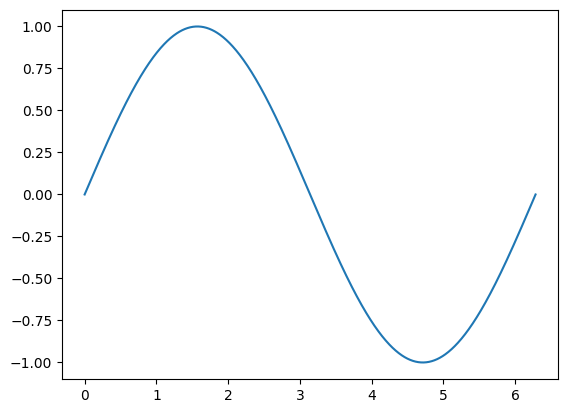

In [2]:
# create 1000 evenly spaced points
x = np.linspace(0, 2*np.pi, 1000)
y = np.sin(x)

plt.plot(x,y) ;


We can just copy and paste our code to see what happens if we change it to be sin(2*x) instead of sin(x).

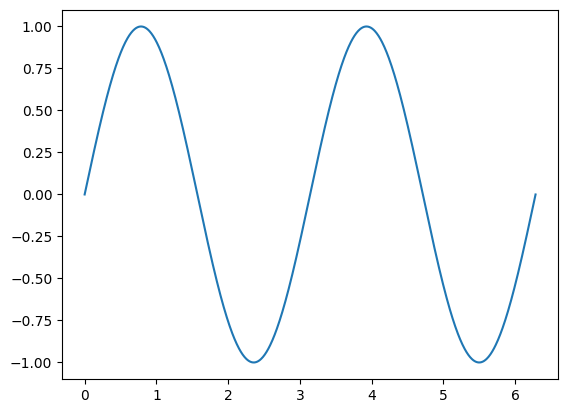

In [3]:
# create 1000 evenly spaced points
x = np.linspace(0, 2*np.pi, 1000)
y = np.sin(2*x)

plt.plot(x,y) ;


But it might make more sense to make a function that takes the frequency as an argument if we want to play around with different values here.

In [4]:
def sinplot(f=1):
  x = np.linspace(0, 2*np.pi, 1000)
  y = np.sin(f*x)
  plt.plot(x,y)
  plt.show() ;


Now we can just rerun our function with different inputs to see what happens.

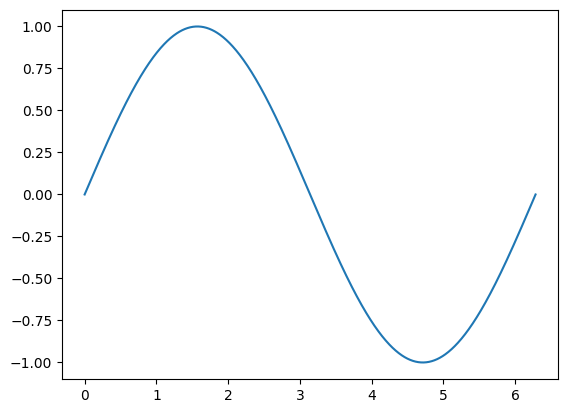

In [5]:
sinplot()


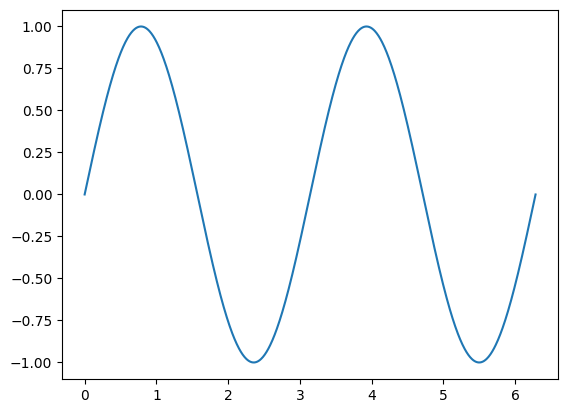

In [6]:
sinplot(2)


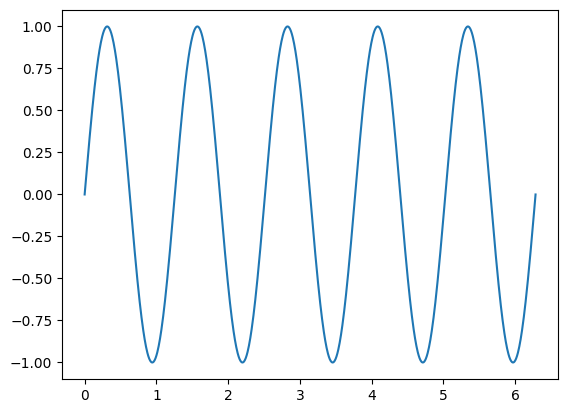

In [7]:
sinplot(5)


## Interactive


Or we can make it way cooler using interact.  This way we can just use a slider to change the value of f on the fly.

In [8]:
interact(sinplot, f=(0.000000,10.000000)) ;


interactive(children=(FloatSlider(value=1.0, description='f', max=10.0), Output()), _dom_classes=('widget-inte…

If we want to play more with interact we can just bring up the help and get some ideas of what we can do.

In [9]:
interact?


Let's try out a few of the examples from the help documentation.

In [10]:
def greeting(text="World"):
  print(f"Hello {text}")

interact(greeting) ;


interactive(children=(Text(value='World', description='text'), Output()), _dom_classes=('widget-interact',))

In [11]:
def greeting(text="World!"):
  print(f"Hello {text}")

interact(greeting, text="universe") ;


interactive(children=(Text(value='universe', description='text'), Output()), _dom_classes=('widget-interact',)…

In [12]:
def greeting(greet="hello", text="World"):
  print(f"{greet} -- {text}")

# interact(greeting, text="universe") ;
interact(greeting, greet="Hola") ;


interactive(children=(Text(value='Hola', description='greet'), Text(value='World', description='text'), Output…

In [13]:
# all arguments must have default values
def greeting(name="", greet="hello", text="World"):
  print(f"{greet} -- {text} -- {name}")

# interact(greeting, text="universe") ;
interact(greeting, greet="Hola") ;


interactive(children=(Text(value='', description='name'), Text(value='Hola', description='greet'), Text(value=…

## @interact Decorator

This uses interact as a decorator instead.  `@interact` goes on top of the function instead of using `interact(func)`.

In [14]:
@interact
def greeting(text="World!"):
  print(f"Hello {text}")


interactive(children=(Text(value='World!', description='text'), Output()), _dom_classes=('widget-interact',))

In [15]:
@interact(text="universe")
def greeting(text="World!"):
  print(f"Hello {text}")


interactive(children=(Text(value='universe', description='text'), Output()), _dom_classes=('widget-interact',)…

In [16]:
@interact(greet="Hola")
def greeting(greet="hello", text="World"):
  print("{} -- {}".format(greet, text))


interactive(children=(Text(value='Hola', description='greet'), Text(value='World', description='text'), Output…

We can also use a list with interact to limit our input options and create a dropdown that lets us pick options from the list.

In [17]:
@interact(text = ["universe", "little bear","World!"])
def greeting(text="World!"):
  print(f"Hello {text}")


interactive(children=(Dropdown(description='text', index=2, options=('universe', 'little bear', 'World!'), val…

Here's an example that uses a boolean input and creates a checkbox.

In [18]:
@interact
def lin_log(log=False):
  x = np.linspace(0.1, 100, 1000)
  y = x
  if log: plt.axes(yscale='log')
  plt.plot(x,y)
  plt.show()


interactive(children=(Checkbox(value=False, description='log'), Output()), _dom_classes=('widget-interact',))

In [19]:
@interact(a=(-100.0,100.0), b=(-100, 100), c=(-100,100))
def multiply(a=1,b=-1,c=1, pos= False):
  if pos: return abs(a*b*c)
  return(a*b*c)


interactive(children=(FloatSlider(value=1.0, description='a', min=-100.0), IntSlider(value=-1, description='b'…

In [22]:
options = ["universe", "little bear","World!"]
@interact(text = sorted(options, key=lambda x: x.lower()) )
def greeting(text="World!"):
  print(f"Hello {text}")


interactive(children=(Dropdown(description='text', index=2, options=('little bear', 'universe', 'World!'), val…

## Your Turn


1. Create a function called `plot_power` that takes in two arguments:  `x_max` and `power`. This function should do the following:
    * Create a variable called `x` which consists of 30 equally spaced points between `-x_max` and `x_max`. (Note: `x_max` can be any positive integer)
    * Create a variable called `y` which is equal to $ x^{power} $ (where `power` is the value specified by the user).
    * Plot y versus x.  

1. Use interact to create sliders with a range of values for `x_max` and `power`.

In [28]:
# Solution 1
@interact
def plotpower(x_max = 100, power = 2) -> None:
  """Given int values of x_max and power, plots a graph of x^power for values of [-x_max, x_max]"""
  x = np.linspace(-1 * x_max, x_max, 30)
  y = x ** power

  plt.plot(x, y)
  plt.show ;

interactive(children=(IntSlider(value=100, description='x_max', max=300, min=-100), IntSlider(value=2, descrip…

In [29]:
# Solution 2
interact(plotpower, x_max = [100, 1_000, 10_000])

interactive(children=(Dropdown(description='x_max', options=(100, 1000, 10000), value=100), IntSlider(value=2,…

<function __main__.plotpower(x_max=100, power=2) -> None>